URL Dataset Created.
                                                  url
0                              https://www.google.com
1                              https://www.amazon.com
2                           https://www.microsoft.com
3                               https://www.apple.com
4                           https://www.wikipedia.org
5                            https://www.linkedin.com
6                              https://www.github.com
7                              https://www.paypal.com
8            http://192.168.1.100/login.php?id=928374
9   http://free-money-prize-login-verify.com/a1b2c3d4
10  http://secure-account-update-login.xyz/verify?...
11  http://paypal-login-security-alert.biz/account...
12  http://x9k2m7p4q8z1-example.com/login?user=123...

Extracted URL Features:
    URL_Length  Dots  Hyphens  Slashes  Digits  Special_Characters  \
0           22     2        0        2       0                   0   
1           22     2        0        2       0            

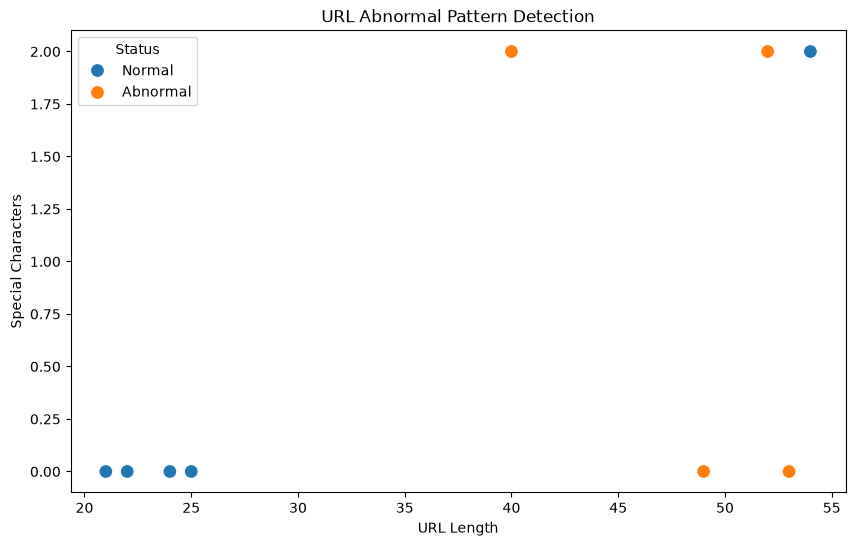

In [1]:
import pandas as pd
import numpy as np
import re

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns


# ---------------- Step 1: Create URL Dataset ----------------

data = {
    "url": [

        # Normal URLs
        "https://www.google.com",
        "https://www.amazon.com",
        "https://www.microsoft.com",
        "https://www.apple.com",
        "https://www.wikipedia.org",
        "https://www.linkedin.com",
        "https://www.github.com",
        "https://www.paypal.com",

        # Abnormal URLs
        "http://192.168.1.100/login.php?id=928374",
        "http://free-money-prize-login-verify.com/a1b2c3d4",
        "http://secure-account-update-login.xyz/verify?id=12345",
        "http://paypal-login-security-alert.biz/account/update",
        "http://x9k2m7p4q8z1-example.com/login?user=123456789"
    ]
}


df = pd.DataFrame(data)

print("URL Dataset Created.")
print(df)


# ---------------- Step 2: Feature Engineering ----------------

def extract_features(url):

    features = []

    # URL Length
    features.append(len(url))

    # Number of dots
    features.append(url.count("."))

    # Number of hyphens
    features.append(url.count("-"))

    # Number of slashes
    features.append(url.count("/"))

    # Number of digits
    features.append(
        sum(c.isdigit() for c in url)
    )

    # Number of special characters
    features.append(
        len(re.findall(r'[@?=&_%]', url))
    )

    # Number of subdomains
    features.append(
        max(url.count(".") - 1, 0)
    )

    # HTTPS presence
    features.append(
        1 if url.startswith("https") else 0
    )

    # IP address presence
    ip_pattern = r'\d{1,3}(\.\d{1,3}){3}'

    features.append(
        1 if re.search(ip_pattern, url) else 0
    )

    return features


# Extract features from URLs

X = np.array([
    extract_features(url)
    for url in df["url"]
])


# Feature names

feature_names = [
    "URL_Length",
    "Dots",
    "Hyphens",
    "Slashes",
    "Digits",
    "Special_Characters",
    "Subdomains",
    "HTTPS",
    "IP_Address"
]


features_df = pd.DataFrame(
    X,
    columns=feature_names
)


print("\nExtracted URL Features:")
print(features_df)


# ---------------- Step 3: Feature Scaling ----------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(features_df)


print("\nFeature Scaling Completed.")


# ---------------- Step 4: Train Anomaly Detection Model ----------------

model = IsolationForest(
    contamination=0.3,
    random_state=42
)

model.fit(X_scaled)


print("\nIsolation Forest Model Trained.")


# ---------------- Step 5: Detect Abnormal Patterns ----------------

predictions = model.predict(X_scaled)


df["Prediction"] = predictions


# 1 = Normal
# -1 = Abnormal

df["Status"] = df["Prediction"].apply(
    lambda x: "Normal" if x == 1 else "Abnormal"
)


print("\nURL Anomaly Detection Results:")

for url, status in zip(
    df["url"],
    df["Status"]
):

    print(
        f"{url} --> {status}"
    )


# ---------------- Step 6: Display Abnormal URLs ----------------

abnormal_urls = df[
    df["Status"] == "Abnormal"
]


print("\nDetected Abnormal URLs:")

print(
    abnormal_urls[
        ["url", "Status"]
    ]
)


# ---------------- Step 7: Visualization ----------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=features_df["URL_Length"],
    y=features_df["Special_Characters"],
    hue=df["Status"],
    s=100
)

plt.title(
    "URL Abnormal Pattern Detection"
)

plt.xlabel(
    "URL Length"
)

plt.ylabel(
    "Special Characters"
)

plt.show()